# 07 — Out-of-time test: do the 2022 results hold in later years?

The 2022 models and explanatory variables are kept; only the outcomes move to later years: federal income tax per resident in 2023 (published by ESTV on 5 November 2026) and the social assistance rate in 2023 and 2024 (2024 partly FSO estimates; 2025 incomplete and not used).

Input: `data/processed/communes_2022.csv`, `data/processed/outcomes_later_years.csv`. Output: `Results/out_of_time/`.

## 1. Setup: how much do communes change from one year to the next?

,Communes,Median 2022,Median later year,Correlation 2022 vs later year
Tax per resident (log),2108.0,6.662,6.666,0.978
"SA rate, 2023",1547.0,1.600,1.600,0.963
"SA rate, 2024 (all)",1475.0,1.600,1.600,0.927
"SA rate, 2024 (no FSO estimates)",721.0,1.400,1.300,0.928


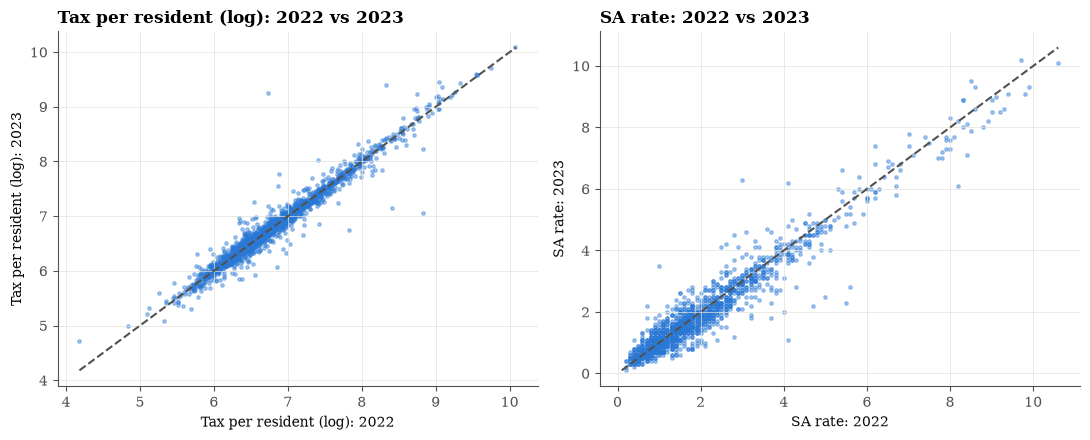

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.append("../code")
import helpers

df, tax_sample, sa_sample = helpers.load_model_samples()
OUT = helpers.results_dir("out_of_time")

# Later outcomes (tax 2023, SA 2023-2024), matched to each commune by its number.
# Every explanatory variable stays 2022.
later = pd.read_csv(helpers.PROCESSED / "outcomes_later_years.csv", encoding="utf-8-sig").set_index("code")
later_columns = ["tax_per_capita_2023", "sa_rate_2023", "sa_rate_2024", "sa_estimate_2024",
                 "population_2023", "foreign_share_2023", "foreign_share_2024"]
for data in (df, tax_sample, sa_sample):
    for col in later_columns:
        data[col] = data["code"].map(later[col])
    data["log_tax_2023"] = np.log(data["tax_per_capita_2023"])

# How similar is each commune from one year to the next?
pairs = [
    ("Tax per resident (log)", tax_sample, "log_tax", "log_tax_2023", None),
    ("SA rate, 2023", sa_sample, "sa_rate", "sa_rate_2023", None),
    ("SA rate, 2024 (all)", sa_sample, "sa_rate", "sa_rate_2024", None),
    ("SA rate, 2024 (no FSO estimates)", sa_sample, "sa_rate", "sa_rate_2024", "sa_estimate_2024"),
]
rows = {}
for label, sample, before, after, flag in pairs:
    data = sample.dropna(subset=[before, after])
    if flag:
        data = data[data[flag] == 0]
    rows[label] = {
        "Communes": len(data),
        "Median 2022": data[before].median(),
        "Median later year": data[after].median(),
        "Correlation 2022 vs later year": data[before].corr(data[after]),
    }
table_years = pd.DataFrame(rows).T.round(3)
table_years.to_csv(OUT / "table_year_to_year.csv")
display(table_years)

# Figure: each commune's value in 2022 against the later year (dashed line = no change)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (label, sample, before, after, flag) in zip(axes, pairs[:2]):
    data = sample.dropna(subset=[before, after])
    ax.scatter(data[before], data[after], s=6, alpha=0.4, color=helpers.COLORS["urban_rural"]["urban"])
    low, high = data[[before, after]].min().min(), data[[before, after]].max().max()
    ax.plot([low, high], [low, high], linestyle="--", color=helpers.INK["secondary"])
    ax.set_xlabel(f"{label.split(',')[0]}: 2022")
    ax.set_ylabel(f"{label.split(',')[0]}: 2023")
    ax.set_title(f"{label.split(',')[0]}: 2022 vs 2023")
    ax.grid(color=helpers.INK["grid"], linewidth=0.5)
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_2022_vs_2023.png")
plt.show()

## 2. Are the coefficients stable?
Same model M4 (2022 controls, canton fixed effects, standard errors clustered by canton), estimated on the same communes for 2022 and for the later year.

In [2]:
import warnings

# Same harmless warning as in notebook 04 (overall F-test with canton fixed effects)
warnings.filterwarnings("ignore", message="covariance of constraints does not have full rank")

controls = helpers.M4_CONTROLS
other_controls = helpers.M4_OTHER_CONTROLS
fit = helpers.fit_clustered
cell = helpers.coef_with_stars

def key_results(data, outcome):
    """The key notebook-04 results for one outcome on one set of communes."""
    m4 = fit(f"{outcome} ~ {controls}", data)
    quad = fit(f"{outcome} ~ {controls} + I(foreign_share**2)", data)
    inter = fit(f"{outcome} ~ {other_controls} + C(urban_rural):foreign_share", data)
    b1, b2 = quad.params["foreign_share"], quad.params["I(foreign_share ** 2)"]
    return {
        "Foreign share (M4)": cell(m4, "foreign_share"),
        "Foreign share squared": f"{b2:.6f}{helpers.stars(quad.pvalues['I(foreign_share ** 2)'])}",
        "Turning point (%)": round(-b1 / (2 * b2), 1),
        "Urban slope": cell(inter, "C(urban_rural)[urban]:foreign_share"),
        "Rural slope": cell(inter, "C(urban_rural)[rural]:foreign_share"),
        "Communes": int(m4.nobs),
    }


# Each pair uses exactly the same communes in both years, so only the year differs
tax_both = tax_sample.dropna(subset=["log_tax_2023"])
sa_2023 = sa_sample.dropna(subset=["sa_rate_2023"])
sa_2024 = sa_sample.dropna(subset=["sa_rate_2024"])
sa_2024_counted = sa_2024[sa_2024["sa_estimate_2024"] == 0]

columns = {
    "Tax 2022": key_results(tax_both, "log_tax"),
    "Tax 2023": key_results(tax_both, "log_tax_2023"),
    "SA 2022": key_results(sa_2023, "sa_rate"),
    "SA 2023": key_results(sa_2023, "sa_rate_2023"),
    "SA 2022 (2024 communes)": key_results(sa_2024, "sa_rate"),
    "SA 2024": key_results(sa_2024, "sa_rate_2024"),
    "SA 2022 (2024 without estimates)": key_results(sa_2024_counted, "sa_rate"),
    "SA 2024 without estimates": key_results(sa_2024_counted, "sa_rate_2024"),
}
table_stability = pd.DataFrame(columns)
table_stability.to_csv(OUT / "table_coefficient_stability.csv")
table_stability

,Tax 2022,Tax 2023,SA 2022,SA 2023,SA 2022 (2024 communes),SA 2024,SA 2022 (2024 without estimates),SA 2024 without estimates
Foreign share (M4),0.0002,-0.0001,0.0532***,0.0498***,0.0556***,0.0524***,0.0341***,0.0256**
Foreign share squared,-0.000690***,-0.000670**,-0.000516,-0.000451,-0.000574,-0.000633,-0.000353,-0.000390
Turning point (%),23.8,23.6,76.7,80.4,74.1,67.0,75.0,59.4
Urban slope,-0.0153***,-0.0160***,0.0620***,0.0581***,0.0632***,0.0577***,0.0418***,0.0303***
Rural slope,0.0150**,0.0146**,0.0548***,0.0474***,0.0567***,0.0553***,0.0279,0.0257
Communes,2108,2108,1547,1547,1475,1475,721,721


## 3. Do the models predict a later year in cantons they have never seen?
Models are trained on 2022 outcomes with the canton folds of notebook 05; each commune's out-of-fold prediction is compared with its 2022 value (same year) and with its later value (2023 or 2024). Reference: each commune's own 2022 value used as the forecast.

In [3]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# The same canton folds as notebook 05: every commune is predicted by a model that
# never saw its canton, trained on 2022 outcomes only
canton_cv = GroupKFold(n_splits=5, shuffle=True, random_state=helpers.SEED)

# Models with the settings chosen by tuning in notebook 05 (section 4)
kernel = ConstantKernel(1.0) * RBF(length_scale=1.0) + WhiteKernel(noise_level=1.0)
models = {
    "OLS": lambda leaf, depth: LinearRegression(),
    "Random forest": lambda leaf, depth: RandomForestRegressor(
        n_estimators=200, max_features=0.33, min_samples_leaf=leaf, random_state=helpers.SEED),
    "Gradient boosting": lambda leaf, depth: HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.03, max_depth=depth, random_state=helpers.SEED),
    "Gaussian process": lambda leaf, depth: make_pipeline(
        StandardScaler(), GaussianProcessRegressor(kernel=kernel, normalize_y=True, random_state=helpers.SEED)),
}
setups = {   # outcome: (communes, 2022 outcome, later outcome, tuned leaf size, tuned tree depth)
    "Tax (log), 2023": (tax_both, "log_tax", "log_tax_2023", 1, 5),
    "SA rate, 2023": (sa_2023, "sa_rate", "sa_rate_2023", 5, 3),
    "SA rate, 2024": (sa_2024, "sa_rate", "sa_rate_2024", 5, 3),
}

rows = []
for label, (data, y_2022, y_later, leaf, depth) in setups.items():
    X = helpers.ml_features(data)
    for name, make_model in models.items():
        pred = cross_val_predict(make_model(leaf, depth), X, data[y_2022], cv=canton_cv,
                                 groups=data["canton"], n_jobs=-1)
        rows.append({"outcome": label, "model": name,
                     "R², same year (2022)": r2_score(data[y_2022], pred),
                     "R², later year": r2_score(data[y_later], pred)})
    # Reference: last year's own value as the forecast (needs the commune's 2022 outcome)
    rows.append({"outcome": label, "model": "Reference: own 2022 value",
                 "R², same year (2022)": np.nan,
                 "R², later year": r2_score(data[y_later], data[y_2022])})

table_forecast = pd.DataFrame(rows).set_index(["outcome", "model"]).round(3)
table_forecast.to_csv(OUT / "table_out_of_time_prediction.csv")
table_forecast

R², same year (2022)  \
outcome         model                                             
Tax (log), 2023 OLS                                       0.101   
                Random forest                             0.206   
                Gradient boosting                         0.207   
                Gaussian process                          0.212   
                Reference: own 2022 value                   NaN   
SA rate, 2023   OLS                                       0.098   
                Random forest                             0.134   
                Gradient boosting                         0.096   
                Gaussian process                          0.130   
                Reference: own 2022 value                   NaN   
SA rate, 2024   OLS                                       0.111   
                Random forest                             0.139   
                Gradient boosting                         0.092   
                Gaussian process                          0.135   
                Reference: own 2022 value                   NaN   

                                           R², later year  
outcome         model                                      
Tax (log), 2023 OLS                                 0.094  
                Random forest                       0.202  
                Gradient boosting                   0.199  
                Gaussian process                    0.201  
                Reference: own 2022 value           0.955  
SA rate, 2023   OLS                                 0.101  
                Random forest                       0.135  
                Gradient boosting                   0.097  
                Gaussian process                    0.137  
                Reference: own 2022 value           0.923  
SA rate, 2024   OLS                                 0.119  
                Random forest                       0.145  
                Gradient boosting                   0.103  
                Gaussian process                    0.126  
                Reference: own 2022 value           0.855

## 4. Changes within each commune: when the foreign share rises, does social assistance rise too?
Sections 2 and 3 compare communes with each other. Here each commune is compared with itself: the change in its outcome between 2022 and the later year is regressed on the change in its foreign share. Everything about a commune that does not change in one or two years (location, lake access, history, reputation, local economy) drops out, which addresses the main limitation of the cross-section: about 95% of the differences between communes persist from year to year and are mostly not measured.

Models: (a) change on change; (b) + canton fixed effects, so each canton can have its own trend; (c) + the change in population (2023 only); (d) = (b) weighted by population, because the rates of very small communes jump from year to year. Standard errors clustered by canton.

Caution: from 2023, persons with protection status S (Ukraine) who have been in Switzerland for 12 months count as permanent residents, so part of the rise in the foreign share comes from refugees allocated to communes by the cantons; their support is recorded in the asylum statistics, not in the social-assistance rate.

,(a) change on change,(b) + canton trends,(c) (b) + population change,(d) (b) weighted by population,Communes,"Change in foreign share: mean (SD), pp"
"Tax per resident (log), 2022 to 2023",-0.0071*** (0.0021),-0.0080*** (0.0019),-0.0052 (0.0036),-0.0023 (0.0028),2106,0.78 (1.09)
"SA rate, 2022 to 2023",0.0182 (0.0107),0.0278* (0.0143),0.0250* (0.0145),-0.0092 (0.0172),1547,0.83 (0.94)
"SA rate, 2022 to 2024",0.0248 (0.0196),0.0396** (0.0184),,0.0194 (0.0317),1475,1.25 (1.27)
"SA rate, 2022 to 2024 (no FSO estimates)",0.0033 (0.0365),0.0050 (0.0175),,-0.0295 (0.0240),721,1.29 (1.04)


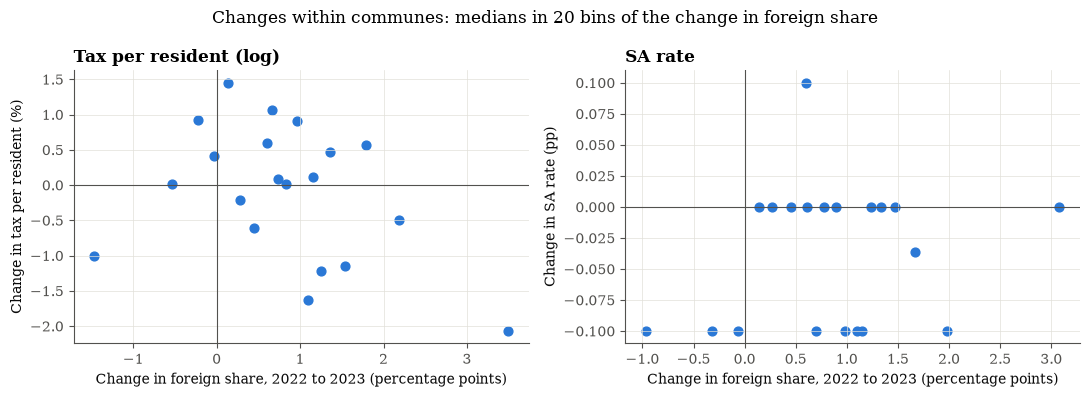

In [4]:
# Changes between 2022 and the later year, for each commune
for data in (tax_sample, sa_sample):
    data["d_foreign_2023"] = data["foreign_share_2023"] - data["foreign_share"]
    data["d_foreign_2024"] = data["foreign_share_2024"] - data["foreign_share"]
    data["d_log_population"] = np.log(data["population_2023"]) - data["log_population"]
tax_sample["d_log_tax"] = tax_sample["log_tax_2023"] - tax_sample["log_tax"]
sa_sample["d_sa_2023"] = sa_sample["sa_rate_2023"] - sa_sample["sa_rate"]
sa_sample["d_sa_2024"] = sa_sample["sa_rate_2024"] - sa_sample["sa_rate"]

changes = {   # label: (communes, change in outcome, change in foreign share)
    "Tax per resident (log), 2022 to 2023": (tax_sample, "d_log_tax", "d_foreign_2023"),
    "SA rate, 2022 to 2023": (sa_sample, "d_sa_2023", "d_foreign_2023"),
    "SA rate, 2022 to 2024": (sa_sample, "d_sa_2024", "d_foreign_2024"),
    "SA rate, 2022 to 2024 (no FSO estimates)": (sa_sample[sa_sample["sa_estimate_2024"] == 0],
                                                 "d_sa_2024", "d_foreign_2024"),
}

rows = {}
for label, (sample, dy, dx) in changes.items():
    data = sample.dropna(subset=[dy, dx, "d_log_population"])
    models = {
        "(a) change on change": helpers.fit_clustered(f"{dy} ~ {dx}", data),
        "(b) + canton trends": helpers.fit_clustered(f"{dy} ~ {dx} + C(canton)", data),
        "(d) (b) weighted by population": helpers.fit_clustered(f"{dy} ~ {dx} + C(canton)", data, weighted=True),
    }
    if dx.endswith("2023"):
        models["(c) (b) + population change"] = helpers.fit_clustered(
            f"{dy} ~ {dx} + d_log_population + C(canton)", data)
    row = {name: f"{helpers.coef_with_stars(m, dx)} ({m.bse[dx]:.4f})" for name, m in models.items()}
    row["Communes"] = len(data)
    row["Change in foreign share: mean (SD), pp"] = f"{data[dx].mean():.2f} ({data[dx].std():.2f})"
    rows[label] = row

table_changes = pd.DataFrame(rows).T[["(a) change on change", "(b) + canton trends",
                                      "(c) (b) + population change", "(d) (b) weighted by population",
                                      "Communes", "Change in foreign share: mean (SD), pp"]].fillna("")
table_changes.to_csv(OUT / "table_changes_within_communes.csv")
display(table_changes)

# Figure: binned changes (20 bins of the change in foreign share)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (label, scale, ylabel) in zip(axes, [("Tax per resident (log), 2022 to 2023", 100, "Change in tax per resident (%)"),
                                             ("SA rate, 2022 to 2023", 1, "Change in SA rate (pp)")]):
    sample, dy, dx = changes[label]
    data = sample.dropna(subset=[dy, dx])
    bins = data.groupby(pd.qcut(data[dx], 20, duplicates="drop"), observed=True).agg(
        x=(dx, "mean"), y=(dy, "median"))
    ax.scatter(bins["x"], bins["y"] * scale, color=helpers.COLORS["urban_rural"]["urban"], s=40)
    ax.axhline(0, color=helpers.INK["secondary"], linewidth=0.8)
    ax.axvline(0, color=helpers.INK["secondary"], linewidth=0.8)
    ax.set_xlabel("Change in foreign share, 2022 to 2023 (percentage points)")
    ax.set_ylabel(ylabel)
    ax.set_title(label.split(",")[0])
    ax.grid(color=helpers.INK["grid"], linewidth=0.5)
fig.suptitle("Changes within communes: medians in 20 bins of the change in foreign share")
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_changes_within_communes.png")
plt.show()

**Interpretation.** Within communes, the evidence is weak. The foreign share rose by 0.8 percentage points on average between 2022 and 2023 (SD 1.1), so the changes are small. Social assistance: the change-on-change coefficients are positive (0.018 to 0.040 pp per point), about half to three quarters of the cross-sectional +0.05, and significant only with canton trends (2023: 0.028*; 2024: 0.040**); weighted by population, or without the FSO estimates of 2024, they are close to zero. Tax: a rise in the foreign share goes with slightly slower growth of tax per resident (−0.8% per point***), but this disappears once the change in population is held constant (−0.5%, not significant) or with population weights: newcomers, including status-S refugees from 2023, raise the population before they appear as taxpayers. One or two years of change are too short and too noisy to confirm or reject the cross-sectional associations; the direction for social assistance is the same, the size smaller and not robust. This is consistent with the cross-sectional association reflecting mostly long-standing differences between communes, which a one-year change cannot reproduce.

## 5. LaTeX versions of the main tables

In [5]:
paper_tables = {
    "table_year_to_year": table_years,
    "table_coefficient_stability": table_stability,
    "table_out_of_time_prediction": table_forecast,
    "table_changes_within_communes": table_changes,
}
for name, table in paper_tables.items():
    latex = table.to_latex(escape=True, na_rep="", float_format="%.3f")
    _ = (OUT / f"{name}.tex").write_text(latex, encoding="utf-8")
print("Saved:", len(paper_tables), "tables")

Saved: 4 tables


## 6. Summary

| Check | Result |
|---|---|
| Year-to-year persistence | communes barely change: correlation between 2022 and 2023 of 0.978 (log tax) and 0.963 (SA rate); 0.927 for SA 2024 |
| Coefficients with later outcomes | tax: M4 ≈ 0 in both years, inverted U with the same peak (23.8% → 23.6%), urban slope −0.015 → −0.016, rural slope +0.015 in both; SA: +0.053 → +0.050 (2023), +0.056 → +0.052 (2024), linear in every year |
| Prediction in unseen cantons and a later year | R² for the later year ≈ R² for 2022 for every model; flexible models still double OLS for tax (≈ 0.20 vs 0.10) and add little for SA (≈ 0.13–0.14 vs 0.10) |
| Changes within communes (2022 to 2023/2024) | SA: positive but smaller (0.018 to 0.040 pp per point) and not robust; tax: −0.8% per point, gone once population change is held constant; changes are small (mean +0.8 pp) and noisy |
| Reference: each commune's own 2022 value | R² 0.955 (tax 2023), 0.923 (SA 2023), 0.855 (SA 2024) |

The 2022 results reappear with the 2023 tax statistics (published 5 November 2026) and the 2023–2024 social-assistance rates, and the models trained on 2022 predict the later year as well as 2022 itself. Because communes change little from one year to the next, this rules out a one-year accident (a data error or a 2022-specific shock) rather than providing an independent sample. About 95% of the differences between communes persist from year to year, while the structural variables explain about 20% of them in unseen cantons: most persistent differences come from commune-specific factors not in the data. SA 2024 is partly FSO estimates; SA 2025 is incomplete (Geneva and Zug missing) and is not used.